
# ZombieNet — Apocalypse CCTV Detector

---
## SECTION 0 — Project Summary

### System Briefing
`ZombieNet` is a fictional apocalypse surveillance system built to classify CCTV images into four categories: `human`, `zombie`, `vampire`, and `skeleton`. In survival terms, this notebook acts like an early-warning filter: it helps separate harmless civilians from creatures that should absolutely not be wandering near the barricades.

### Why It "Saves Humanity"
In a real emergency monitoring scenario, security teams cannot manually inspect every camera frame. A CNN can automate first-pass screening, flag suspicious targets, and reduce reaction time when something dangerous enters the scene.

### Dataset Used
This project uses a **custom local dataset** stored in `dataset/train` and `dataset/val`. The images were collected with a crawler, then manually cleaned and sorted into four classes:
- `human`
- `zombie`
- `vampire`
- `skeleton`

The current dataset contains **396 cleaned images** in total:
- **253 training images**
- **143 validation images**

### CNN Architecture
ZombieNet uses **MobileNetV2** with **transfer learning**:
- pretrained on **ImageNet**
- convolutional base frozen during training
- custom classification head added for apocalypse classes

This is a strong choice for a university project because it trains faster than a CNN from scratch and still benefits from rich visual features learned on a very large dataset.

### How To Run
1. Keep the `dataset/` folder in the project root.
2. Run the notebook from top to bottom.
3. Let the training stage save the best checkpoint as `zombienet_best.keras`.
4. Review the evaluation report and threat demo to inspect predictions.

### Example Use Case
Imagine this model deployed on **CCTV feeds at the entrance of a quarantine zone**. When ZombieNet spots a zombie or another monster class, it can trigger a warning before the threat reaches survivors.

> Deploy on CCTV cameras to detect zombie infiltration before the gates fall.



---
## SECTION 1 — Imports & Setup

This cell loads the core libraries, fixes the random seed for reproducibility, and starts the surveillance system.


In [1]:

import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"  # Keep the bunker radio a little quieter.
os.environ["KERAS_HOME"] = os.path.join(os.getcwd(), ".keras")
os.makedirs(os.environ["KERAS_HOME"], exist_ok=True)

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.preprocessing.image import ImageDataGenerator, load_img, img_to_array

from sklearn.metrics import classification_report, confusion_matrix

SEED = 42
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32
PROJECT_NAME = "ZombieNet — Apocalypse CCTV Detector"
IMAGE_EXTENSIONS = (".png", ".jpg", ".jpeg", ".bmp", ".gif")

np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

plt.style.use("seaborn-v0_8-whitegrid")
sns.set_theme(style="whitegrid", context="notebook")

print("🧟 ZombieNet initializing... stay safe out there.")
print(f"TensorFlow version: {tf.__version__}")


🧟 ZombieNet initializing... stay safe out there.
TensorFlow version: 2.21.0



---
## SECTION 2 — Dataset Loading (Local Dataset Only)

This project submission uses the **local crawler-built dataset** that was cleaned and organized manually. That keeps the notebook faithful to the actual project data and avoids depending on an external source during grading.

**Professor note:** the next code cell includes a commented Kaggle API template with placeholder credentials. It is left there only as a reference for how this section could be adapted later. The active code uses the local `dataset/` folders only.



This cell verifies the train/validation folder structure, defines helper functions, and prepares class metadata for the rest of the notebook.


In [2]:

# Optional Kaggle template for reference only:
# import os
# os.environ['KAGGLE_USERNAME'] = 'YOUR_USERNAME'
# os.environ['KAGGLE_KEY'] = 'YOUR_TOKEN'
# import kaggle
# kaggle.api.dataset_download_files(
#     'DATASET_NAME_HERE',
#     path='./dataset',
#     unzip=True
# )

TRAIN_DIR = os.path.join("dataset", "train")
VAL_DIR = os.path.join("dataset", "val")


def list_image_files(folder_path):
    files = []
    for file_name in sorted(os.listdir(folder_path)):
        file_path = os.path.join(folder_path, file_name)
        if os.path.isfile(file_path) and file_name.lower().endswith(IMAGE_EXTENSIONS):
            files.append(file_path)
    return files


def count_images_by_class(base_dir):
    counts = {}
    for class_name in sorted(os.listdir(base_dir)):
        class_path = os.path.join(base_dir, class_name)
        if os.path.isdir(class_path):
            counts[class_name] = len(list_image_files(class_path))
    return counts


if not os.path.isdir(TRAIN_DIR) or not os.path.isdir(VAL_DIR):
    raise FileNotFoundError(
        "Expected dataset folders at 'dataset/train' and 'dataset/val'."
    )

class_names = [
    class_name
    for class_name in sorted(os.listdir(TRAIN_DIR))
    if os.path.isdir(os.path.join(TRAIN_DIR, class_name))
]
val_class_names = [
    class_name
    for class_name in sorted(os.listdir(VAL_DIR))
    if os.path.isdir(os.path.join(VAL_DIR, class_name))
]

if class_names != val_class_names:
    raise ValueError("Train and validation folders must contain the same class names.")

train_counts = count_images_by_class(TRAIN_DIR)
val_counts = count_images_by_class(VAL_DIR)
num_classes = len(class_names)

print("ZombieNet dataset structure verified.")
print(f"Classes detected: {class_names}")
for split_name, split_dir in [("train", TRAIN_DIR), ("val", VAL_DIR)]:
    print(f"\n{split_name.upper()} folders:")
    for class_name in class_names:
        print(f"- {split_dir}/{class_name}")


ZombieNet dataset structure verified.
Classes detected: ['human', 'skeleton', 'vampire', 'zombie']

TRAIN folders:
- dataset/train/human
- dataset/train/skeleton
- dataset/train/vampire
- dataset/train/zombie

VAL folders:
- dataset/val/human
- dataset/val/skeleton
- dataset/val/vampire
- dataset/val/zombie



---
## SECTION 3 — Data Exploration & Visualization

This cell counts the images in each class and plots the class distribution so we can inspect whether the apocalypse roster is reasonably balanced.


Class distribution report:
- Human     | train:  71 | val:  36 | total: 107
- Skeleton  | train:  58 | val:  36 | total:  94
- Vampire   | train:  69 | val:  37 | total: 106
- Zombie    | train:  55 | val:  34 | total:  89


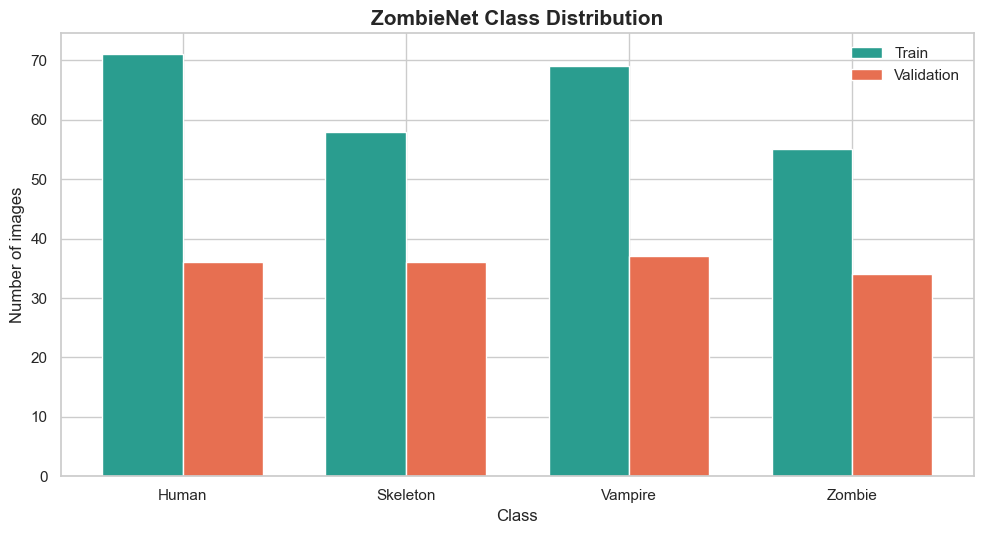

In [3]:

print("Class distribution report:")
for class_name in class_names:
    total_count = train_counts[class_name] + val_counts[class_name]
    print(
        f"- {class_name.capitalize():<9} | train: {train_counts[class_name]:>3} | "
        f"val: {val_counts[class_name]:>3} | total: {total_count:>3}"
    )

train_values = [train_counts[class_name] for class_name in class_names]
val_values = [val_counts[class_name] for class_name in class_names]
x_positions = np.arange(len(class_names))
bar_width = 0.36

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.bar(x_positions - bar_width / 2, train_values, width=bar_width, label="Train", color="#2a9d8f")
ax.bar(x_positions + bar_width / 2, val_values, width=bar_width, label="Validation", color="#e76f51")
ax.set_title("ZombieNet Class Distribution", fontsize=15, fontweight="bold")
ax.set_xlabel("Class")
ax.set_ylabel("Number of images")
ax.set_xticks(x_positions)
ax.set_xticklabels([class_name.capitalize() for class_name in class_names])
ax.legend()
plt.tight_layout()
plt.show()



This cell displays at least five examples from each class so the visual differences between civilians and monsters are easy to inspect.


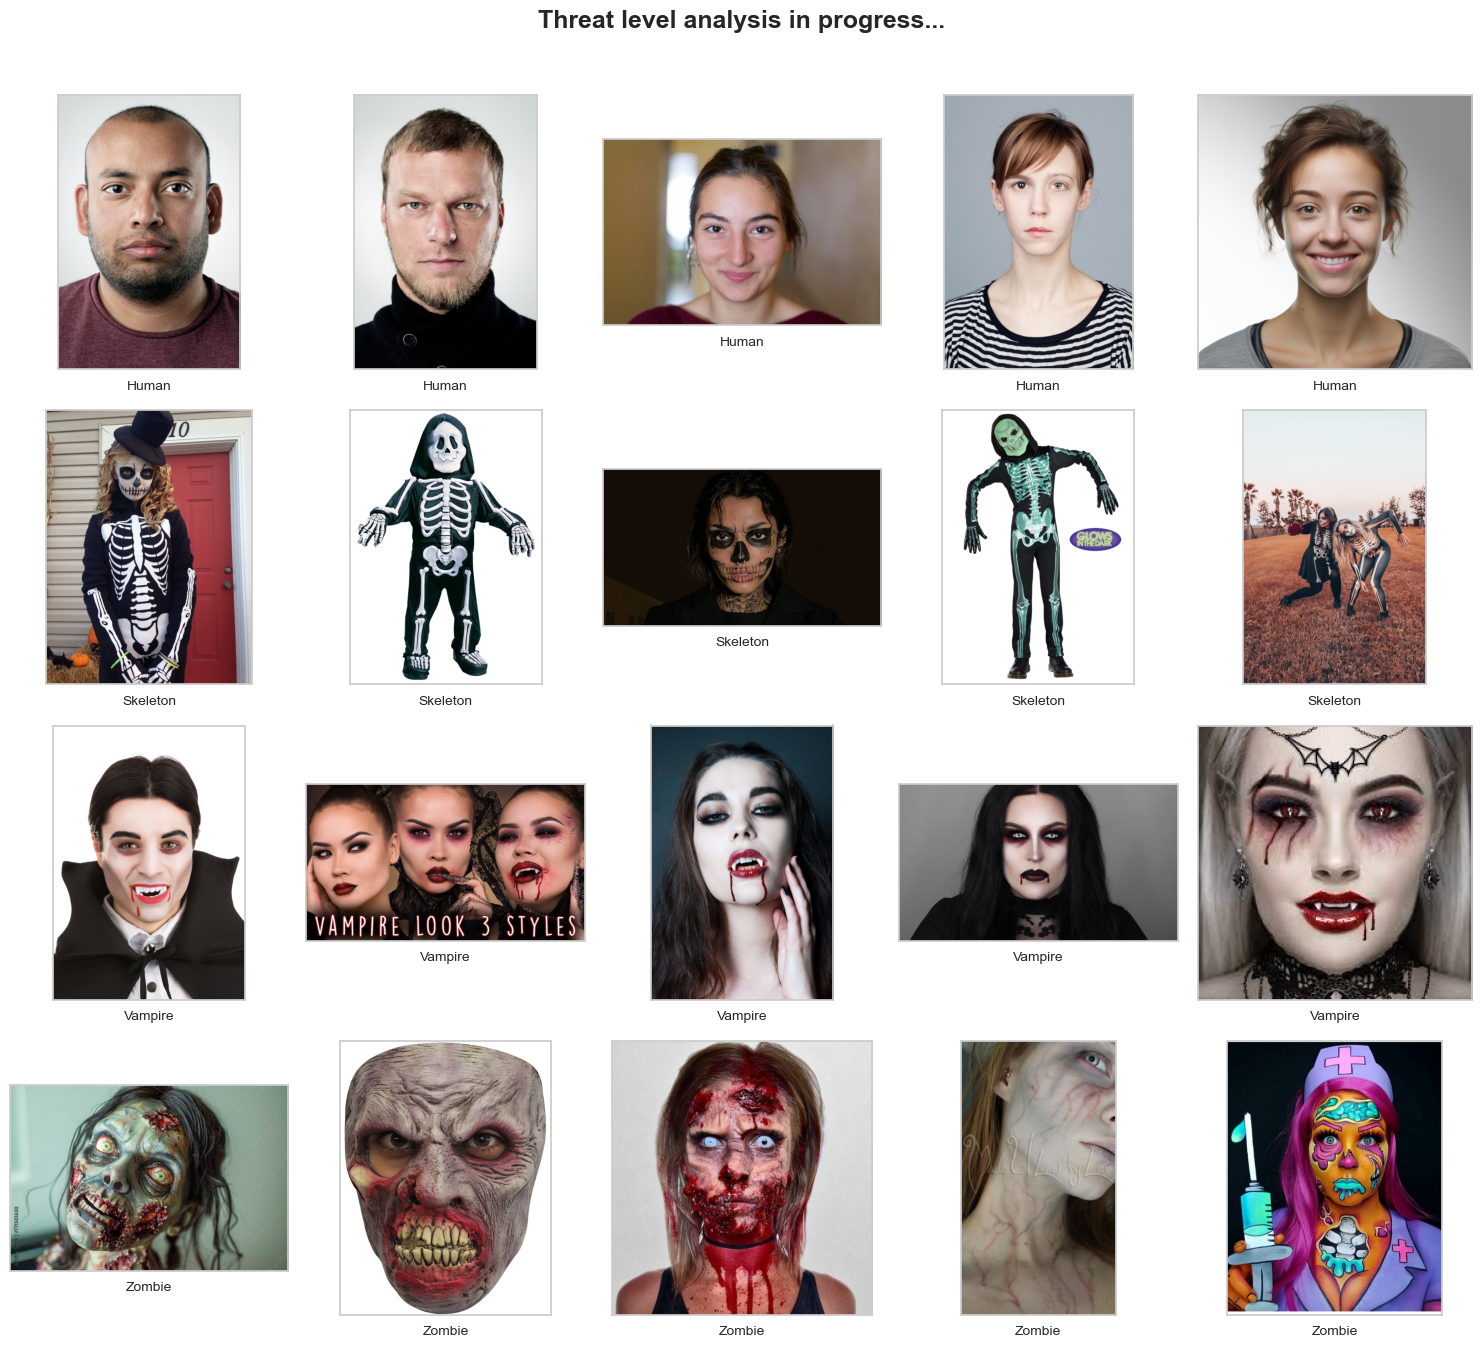

In [4]:

sample_count = 5
fig, axes = plt.subplots(len(class_names), sample_count, figsize=(sample_count * 3, len(class_names) * 3.3))

for row_index, class_name in enumerate(class_names):
    class_folder = os.path.join(TRAIN_DIR, class_name)
    sample_paths = list_image_files(class_folder)[:sample_count]

    for col_index in range(sample_count):
        ax = axes[row_index, col_index]
        if col_index < len(sample_paths):
            image = Image.open(sample_paths[col_index]).convert("RGB")
            ax.imshow(image)
            ax.set_xlabel(class_name.capitalize(), fontsize=10, labelpad=8)
        else:
            ax.text(0.5, 0.5, "No image", ha="center", va="center", fontsize=11)
        ax.set_xticks([])
        ax.set_yticks([])

fig.suptitle("Threat level analysis in progress...", fontsize=18, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()



---
## SECTION 4 — Data Preprocessing & Augmentation

This cell builds the training and validation generators with MobileNetV2-compatible image size, classroom-friendly normalization, and basic augmentation to make the detector less fragile.


In [5]:

train_datagen = ImageDataGenerator(
    rescale=1.0 / 255.0,
    rotation_range=20,
    zoom_range=0.2,
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=True,
    fill_mode="nearest"
)

val_datagen = ImageDataGenerator(rescale=1.0 / 255.0)

train_generator = train_datagen.flow_from_directory(
    TRAIN_DIR,
    target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=True,
    seed=SEED
)

val_generator = val_datagen.flow_from_directory(
    VAL_DIR,
    target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=False
)

index_to_class = {index: class_name for class_name, index in train_generator.class_indices.items()}
print("Class index mapping:", train_generator.class_indices)


Found 253 images belonging to 4 classes.
Found 143 images belonging to 4 classes.
Class index mapping: {'human': 0, 'skeleton': 1, 'vampire': 2, 'zombie': 3}



---
## SECTION 5 — Model Architecture (Transfer Learning)

Transfer learning is a strong fit here because the dataset is relatively small, while MobileNetV2 already knows how to detect useful visual patterns such as shapes, edges, textures, and object parts. Instead of learning everything from scratch, ZombieNet reuses those pretrained features and only learns the final apocalypse-specific classifier.



This cell loads MobileNetV2 with ImageNet weights, freezes its feature extractor, and attaches a custom classifier head for the four threat classes.


In [6]:

base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=IMAGE_SIZE + (3,)
)
base_model.trainable = False  # The pretrained scout stays frozen for the first mission.

inputs = layers.Input(shape=IMAGE_SIZE + (3,), name="cctv_frame")
# The generators output values in [0, 1], so we convert to MobileNetV2's expected [-1, 1] range here.
x = layers.Rescaling(scale=2.0, offset=-1.0, name="mobilenetv2_input_scaling")(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D(name="global_average_pool")(x)
x = layers.Dense(128, activation="relu", name="dense_relay")(x)
x = layers.Dropout(0.3, name="dropout_bunker")(x)
outputs = layers.Dense(num_classes, activation="softmax", name="threat_classifier")(x)

model = models.Model(inputs=inputs, outputs=outputs, name="ZombieNet_MobileNetV2")
model.summary()


Model: "ZombieNet_MobileNetV2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ cctv_frame (InputLayer)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_input_scaling       │ (None, 224, 224, 3)    │             0 │
│ (Rescaling)                     │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pool             │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_relay (Dense)             │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_bunker (Dropout)        │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ threat_classifier (Dense)       │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,468 (9.24 MB)

 Trainable params: 164,484 (642.52 KB)

 Non-trainable params: 2,257,984 (8.61 MB)


---
## SECTION 6 — Training

This cell compiles the model, sets the checkpoint and early stopping callbacks, and starts training. The best version of ZombieNet is saved automatically.


In [7]:

best_model_path = "zombienet_best.keras"

early_stopping = callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

model_checkpoint = callbacks.ModelCheckpoint(
    filepath=best_model_path,
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

model.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=20,
    callbacks=[early_stopping, model_checkpoint],
    verbose=2
)


Epoch 1/20

Epoch 1: val_loss improved from None to 1.21899, saving model to zombienet_best.keras

Epoch 1: finished saving model to zombienet_best.keras
8/8 - 25s - 3s/step - accuracy: 0.3360 - loss: 1.4779 - val_accuracy: 0.4196 - val_loss: 1.2190
Epoch 2/20

Epoch 2: val_loss improved from 1.21899 to 1.07621, saving model to zombienet_best.keras

Epoch 2: finished saving model to zombienet_best.keras
8/8 - 23s - 3s/step - accuracy: 0.4545 - loss: 1.2445 - val_accuracy: 0.5245 - val_loss: 1.0762
Epoch 3/20

Epoch 3: val_loss improved from 1.07621 to 0.92526, saving model to zombienet_best.keras

Epoch 3: finished saving model to zombienet_best.keras
8/8 - 19s - 2s/step - accuracy: 0.5138 - loss: 1.1500 - val_accuracy: 0.6224 - val_loss: 0.9253
Epoch 4/20

Epoch 4: val_loss improved from 0.92526 to 0.82308, saving model to zombienet_best.keras

Epoch 4: finished saving model to zombienet_best.keras
8/8 - 17s - 2s/step - accuracy: 0.6285 - loss: 0.9702 - val_accuracy: 0.6853 - val_loss


---
## SECTION 7 — Training Results Visualization

This cell plots how accuracy and loss evolved during training, which makes it easier to spot overfitting or stalled learning.


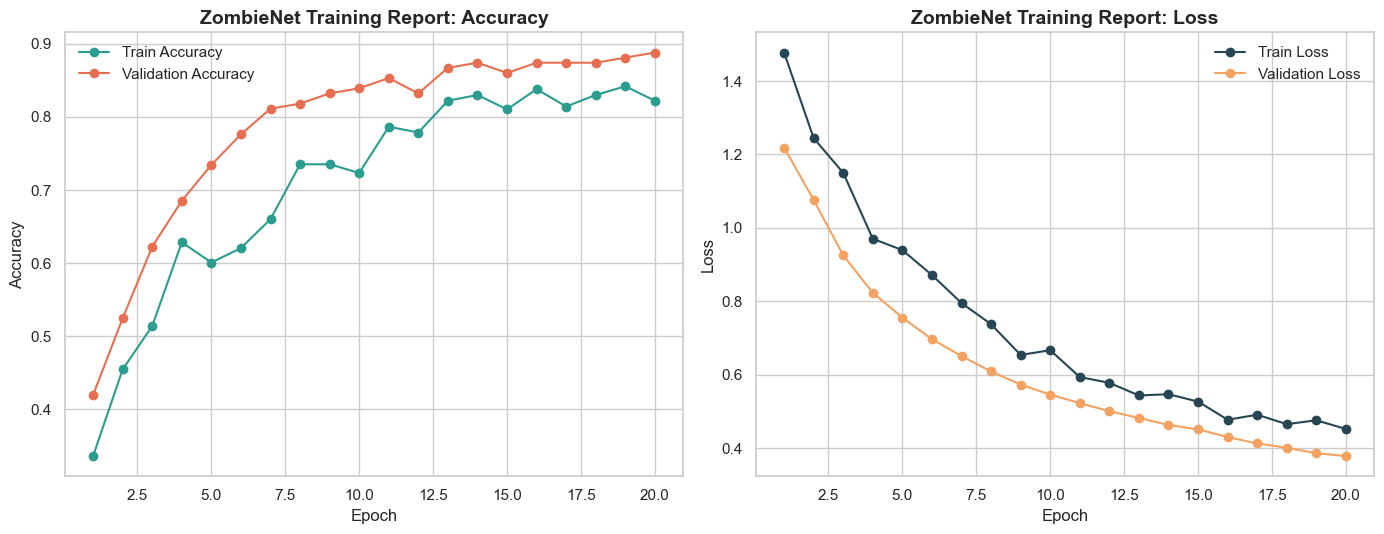

In [8]:

history_data = history.history
epoch_range = range(1, len(history_data["accuracy"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

axes[0].plot(epoch_range, history_data["accuracy"], marker="o", label="Train Accuracy", color="#2a9d8f")
axes[0].plot(epoch_range, history_data["val_accuracy"], marker="o", label="Validation Accuracy", color="#e76f51")
axes[0].set_title("ZombieNet Training Report: Accuracy", fontsize=14, fontweight="bold")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

axes[1].plot(epoch_range, history_data["loss"], marker="o", label="Train Loss", color="#264653")
axes[1].plot(epoch_range, history_data["val_loss"], marker="o", label="Validation Loss", color="#f4a261")
axes[1].set_title("ZombieNet Training Report: Loss", fontsize=14, fontweight="bold")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()

plt.tight_layout()
plt.show()



---
## SECTION 8 — Evaluation

This cell evaluates the best saved checkpoint, prints the final validation accuracy, and generates a full classification report with precision, recall, and F1-score for each class.


In [9]:

evaluation_model = tf.keras.models.load_model(best_model_path) if os.path.exists(best_model_path) else model

val_loss, val_accuracy = evaluation_model.evaluate(val_generator, verbose=0)
print(f"Final validation accuracy: {val_accuracy:.2%}")

val_generator.reset()
val_probabilities = evaluation_model.predict(val_generator, verbose=0)
val_predictions = np.argmax(val_probabilities, axis=1)
true_labels = val_generator.classes

print("\nClassification report:")
print(
    classification_report(
        true_labels,
        val_predictions,
        target_names=class_names,
        digits=3,
        zero_division=0
    )
)


Final validation accuracy: 88.81%

Classification report:
              precision    recall  f1-score   support

       human      0.850     0.944     0.895        36
    skeleton      0.943     0.917     0.930        36
     vampire      0.897     0.946     0.921        37
      zombie      0.862     0.735     0.794        34

    accuracy                          0.888       143
   macro avg      0.888     0.886     0.885       143
weighted avg      0.889     0.888     0.886       143




This cell visualizes the confusion matrix so we can see which creatures ZombieNet mixes up under battlefield conditions.


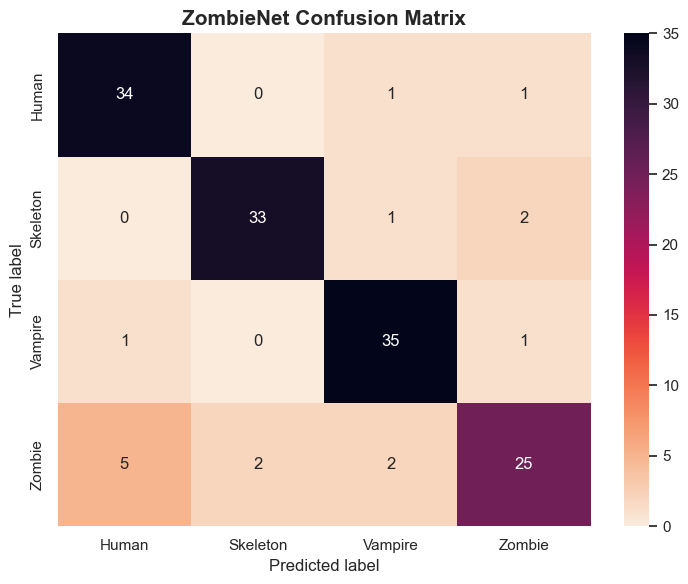

In [10]:

# If human recall is low, we're all doomed.
conf_matrix = confusion_matrix(true_labels, val_predictions)

plt.figure(figsize=(7.5, 6))
sns.heatmap(
    conf_matrix,
    annot=True,
    fmt="d",
    cmap="rocket_r",
    xticklabels=[class_name.capitalize() for class_name in class_names],
    yticklabels=[class_name.capitalize() for class_name in class_names]
)
plt.title("ZombieNet Confusion Matrix", fontsize=15, fontweight="bold")
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.tight_layout()
plt.show()



---
## SECTION 9 — Apocalypse Threat Demo

This cell runs a small CCTV-style demo on validation images, showing the predicted class, confidence score, and a threat message for each detected target.


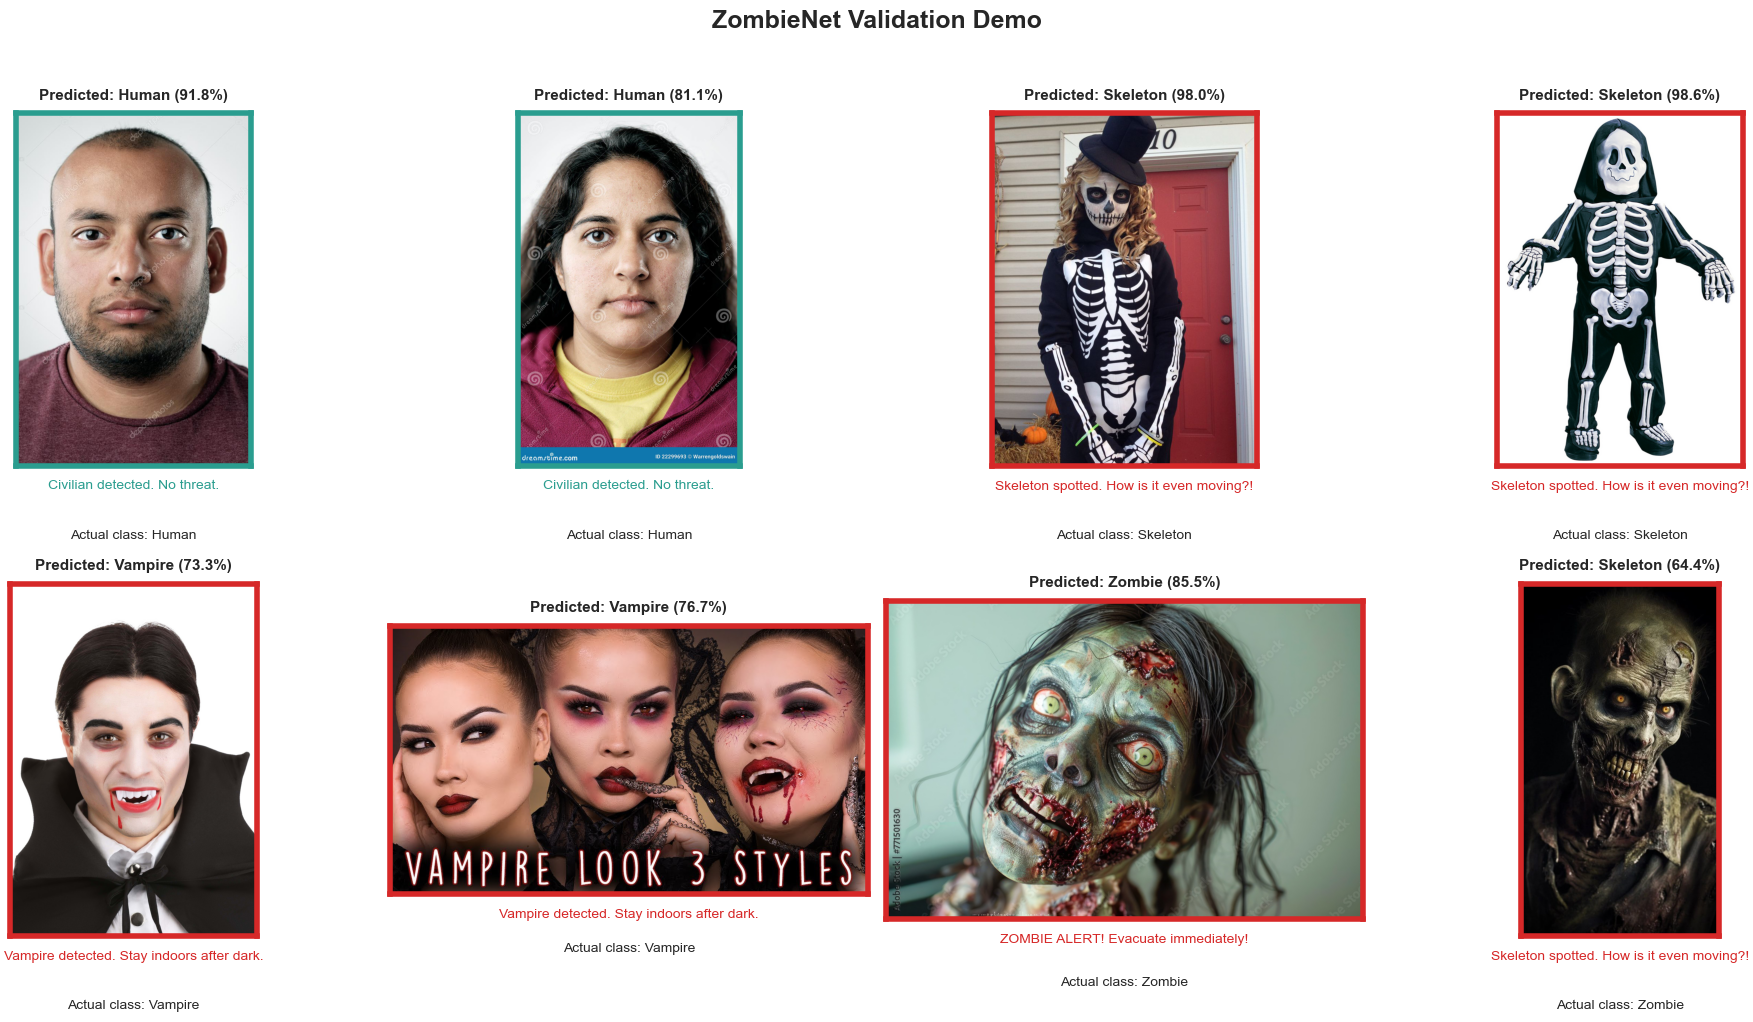

In [11]:

threat_messages = {
    "human": "Civilian detected. No threat.",
    "zombie": "ZOMBIE ALERT! Evacuate immediately!",
    "vampire": "Vampire detected. Stay indoors after dark.",
    "skeleton": "Skeleton spotted. How is it even moving?!"
}

border_colors = {
    "human": "#2a9d8f",
    "zombie": "#d62828",
    "vampire": "#d62828",
    "skeleton": "#d62828"
}

demo_image_paths = []
for class_name in class_names:
    class_folder = os.path.join(VAL_DIR, class_name)
    demo_image_paths.extend(list_image_files(class_folder)[:2])

demo_image_paths = demo_image_paths[:8]
rows, cols = 2, 4
fig, axes = plt.subplots(rows, cols, figsize=(20, 10))
axes = axes.flatten()

for ax, image_path in zip(axes, demo_image_paths):
    actual_class = os.path.basename(os.path.dirname(image_path))

    display_image = Image.open(image_path).convert("RGB")
    predict_image = load_img(image_path, target_size=IMAGE_SIZE)
    predict_array = img_to_array(predict_image) / 255.0
    predict_array = np.expand_dims(predict_array, axis=0)

    probabilities = evaluation_model.predict(predict_array, verbose=0)[0]
    predicted_index = int(np.argmax(probabilities))
    predicted_class = index_to_class[predicted_index]
    confidence = float(probabilities[predicted_index])

    if confidence < 0.50:
        threat_message = "Unidentified creature. Proceed with caution."
    else:
        threat_message = threat_messages[predicted_class]

    border_color = border_colors.get(predicted_class, "#d62828")

    ax.imshow(display_image)
    ax.set_title(
        f"Predicted: {predicted_class.capitalize()} ({confidence * 100:.1f}%)",
        fontsize=11,
        fontweight="bold",
        pad=10
    )
    ax.set_xlabel(threat_message, fontsize=10, color=border_color, labelpad=10)
    ax.text(0.5, -0.18, f"Actual class: {actual_class.capitalize()}", transform=ax.transAxes,
            ha="center", va="top", fontsize=10)
    ax.set_xticks([])
    ax.set_yticks([])

    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(4)
        spine.set_color("#2a9d8f" if predicted_class == "human" else "#d62828")

for ax in axes[len(demo_image_paths):]:
    ax.axis("off")

fig.suptitle("ZombieNet Validation Demo", fontsize=18, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()



---
## SECTION 10 — Conclusion

### Survival Report
ZombieNet successfully learned to separate four categories from the custom monster-vs-human dataset by reusing MobileNetV2 as a pretrained visual feature extractor. Even with a relatively small dataset, transfer learning makes the classifier practical, fast to train, and easier to explain in an academic setting.

### Strengths
- strong starting features from ImageNet pretraining
- lightweight architecture compared with larger CNNs
- clean end-to-end pipeline from exploration to demo prediction

### Weaknesses
- the dataset is still small for a real surveillance system
- some monster classes may look visually similar in low-quality frames
- single-image classification ignores motion and temporal context from video

### ZombieNet v2.0 Improvements
- collect more varied CCTV-style images
- fine-tune the last MobileNetV2 blocks after initial training
- add stronger night-time and blur augmentation
- evaluate on short video sequences instead of isolated frames

### Final Transmission
**Humanity's last line of defense... is a CNN.**
